# DeepLagField: Time-Varying AR Dynamics

Build the order/dynamics model, generate a small balanced coefficient dataset, and train with explicit losses. This runnable example uses two epochs on a small dataset, not the full published benchmark. Forward calculations, loss values, and gradients are separately regression-tested against the reference implementation.


In [1]:
import os
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import neuralfieldmanifold as nfm

torch.manual_seed(42)
dataset = nfm.training.make_tvar_dataset(n_per_family=10, n_samples=600, seed=123,
                                        coefficient_width=10, workers=min(8, os.cpu_count() or 1))
train_data, validation_data = nfm.training.split_dataset(dataset, train_fraction=.8, seed=42)


In [2]:
train_loader = DataLoader(TensorDataset(torch.from_numpy(train_data.signals), torch.from_numpy(train_data.orders)),
                          batch_size=256, shuffle=True)
validation_loader = DataLoader(TensorDataset(torch.from_numpy(validation_data.signals), torch.from_numpy(validation_data.orders)),
                               batch_size=256)
model = nfm.models.DeepLagField(sequence_length=600, hidden_size=128)
weights = nfm.training.LossWeights(reconstruction=5, order_classification=5,
                                  energy=.2, smoothness=5, order_penalty=0)
config = nfm.training.TrainingConfig(epochs=2, weights=weights, stochastic_validation=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
history = nfm.training.train(model, train_loader, validation_loader=validation_loader, config=config, device=device)


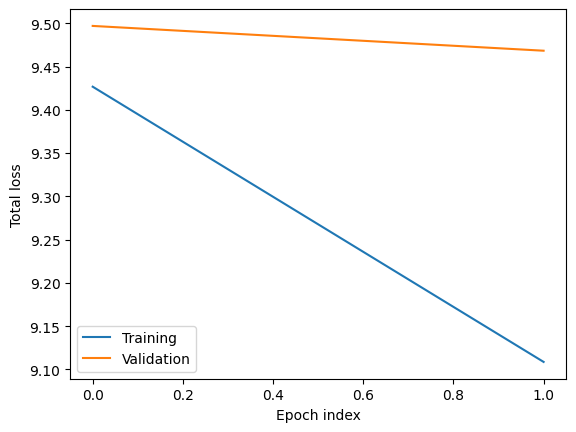

{'prediction_mse': 0.23918141424655914, 'coefficient_mse': 0.01570030301809311, 'order_accuracy': 0.3125, 'within_one_accuracy': 0.5625, 'order_mae': 1.4375, 'order_relative_error': 0.4864583333333333}


In [3]:
plt.plot([row['train']['total'] for row in history], label='Training')
plt.plot([row['validation']['total'] for row in history], label='Validation')
plt.xlabel('Epoch index')
plt.ylabel('Total loss')
plt.legend()
plt.show()
metrics = nfm.training.evaluate(model, validation_data.signals,
                                true_coefficients=validation_data.coefficients[:, :, :6],
                                true_orders=validation_data.orders, device=device)
print({key: value for key, value in metrics.items() if np.isscalar(value)})


Evaluation is deterministic by default. For reference stochastic evaluations, request `sample_order=True` and reset the same PyTorch random state. Reproducing an entire training run additionally requires its initial weights, dataset, split, batch order, and device settings.
